In [3]:
import pandas as pd

ingr = pd.read_csv("data/flavor_network_data/ingr_comp/ingr_info.tsv", sep="\t")
comp = pd.read_csv("data/flavor_network_data/ingr_comp/comp_info.tsv", sep="\t")

# ingr_comp has no header — read with names
ic = pd.read_csv("data/flavor_network_data/ingr_comp/ingr_comp.tsv", sep="\t", comment="#",
                 names=["ingredient_id", "compound_id"])

edges = pd.read_csv("data/flavor_network_data/flavor_network_backbone/flavor_network_backbone_edges.tsv", sep="\t",
                    names=["src", "dst", "weight"])
# nodes: inspect first — probably no header
nodes = pd.read_csv("data/flavor_network_data/flavor_network_backbone/flavor_network_backbone_nodes.tsv", sep="\t", header=None,
                    names=["name","x","y","val","R","G","B"])

# recipes: no header, ragged lines
with open("data/flavor_network_data/scirep-cuisines-detail/allr_recipes.txt") as f:
    recipes = [line.rstrip("\n").split("\t") for line in f]
recipes = [r for r in recipes if len(r) > 1]

In [10]:
# Clean the '# ' prefix on the first column of ingr and comp
ingr = ingr.rename(columns={"# id": "id"})
comp = comp.rename(columns={"# id": "id"})

# Make sure ids are integers (not strings) for merges to work
ingr["id"] = ingr["id"].astype(int)
comp["id"] = comp["id"].astype(int)
ic["ingredient_id"] = ic["ingredient_id"].astype(int)
ic["compound_id"]   = ic["compound_id"].astype(int)

print("ingr :", list(ingr.columns))
print("comp :", list(comp.columns))
print("ic   :", list(ic.columns))
print("edges:", list(edges.columns))
print("nodes:", list(nodes.columns))

ingr : ['id', 'ingredient name', 'category']
comp : ['id', 'Compound name', 'CAS number']
ic   : ['ingredient_id', 'compound_id']
edges: ['src', 'dst', 'weight']
nodes: ['name', 'x', 'y', 'val', 'R', 'G', 'B']


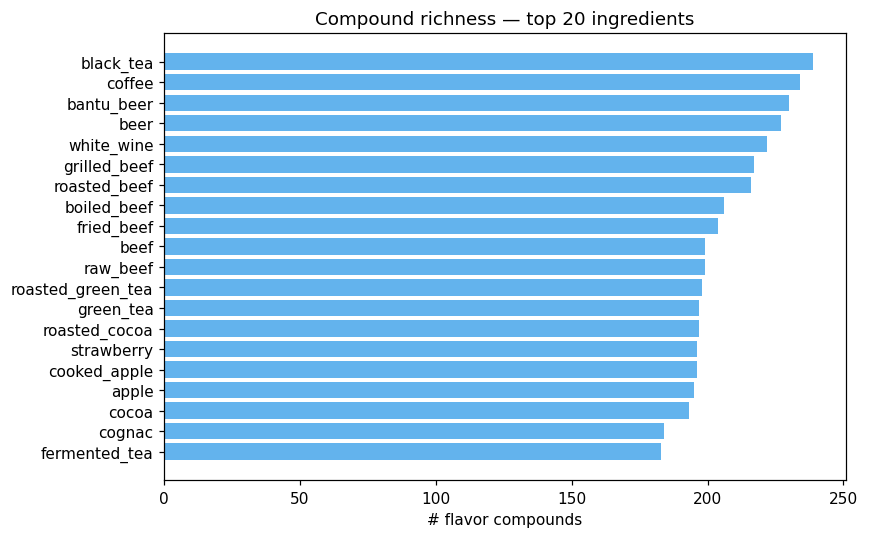

In [11]:
import matplotlib.pyplot as plt

rich = (ic.groupby("ingredient_id").size()
          .reset_index(name="n_compounds")
          .merge(ingr, left_on="ingredient_id", right_on="id", how="left")
          .sort_values("n_compounds", ascending=False).head(20))

fig, ax = plt.subplots(figsize=(8, 5), dpi=110)
ax.barh(rich["ingredient name"][::-1], rich["n_compounds"][::-1], color="#63b3ed")
ax.set_xlabel("# flavor compounds")
ax.set_title("Compound richness — top 20 ingredients")
plt.tight_layout()
plt.show()

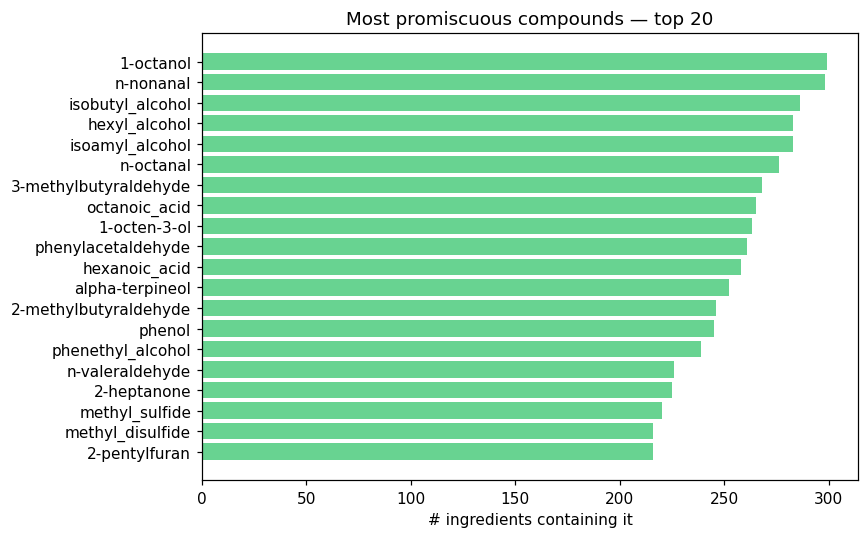

In [12]:
prom = (ic.groupby("compound_id").size()
          .reset_index(name="n_ingredients")
          .merge(comp, left_on="compound_id", right_on="id", how="left")
          .sort_values("n_ingredients", ascending=False).head(20))

fig, ax = plt.subplots(figsize=(8, 5), dpi=110)
ax.barh(prom["Compound name"][::-1], prom["n_ingredients"][::-1], color="#68d391")
ax.set_xlabel("# ingredients containing it")
ax.set_title("Most promiscuous compounds — top 20")
plt.tight_layout()
plt.show()

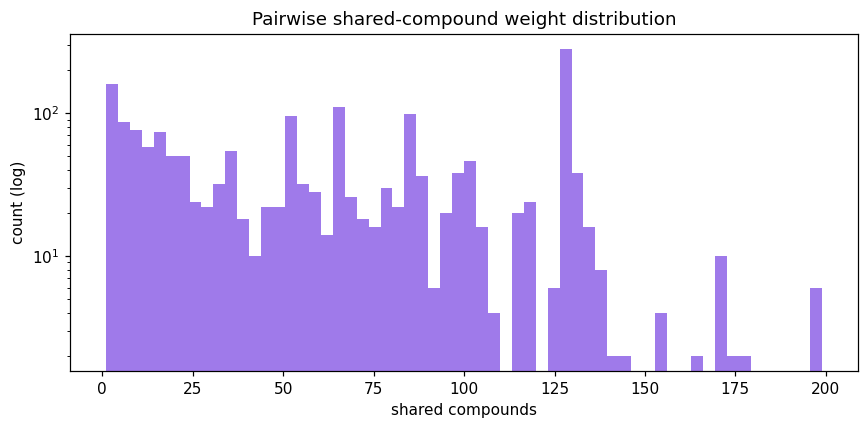

count    1834.000000
mean       63.648855
std        46.651836
min         1.000000
25%        18.000000
50%        62.000000
75%       102.000000
max       199.000000
Name: weight, dtype: float64


In [13]:
fig, ax = plt.subplots(figsize=(8, 4), dpi=110)
ax.hist(edges["weight"], bins=60, color="#9f7aea")
ax.set_yscale("log")
ax.set_xlabel("shared compounds")
ax.set_ylabel("count (log)")
ax.set_title("Pairwise shared-compound weight distribution")
plt.tight_layout()
plt.show()

print(edges["weight"].describe())

In [14]:
top = edges.sort_values("weight", ascending=False).head(15)
print(top.to_string(index=False))

         src          dst  weight
    raw beef         beef     199
    raw beef roasted beef     199
        beef roasted beef     199
    raw beef roasted beef     199
        beef roasted beef     199
    raw beef         beef     199
   black tea    green tea     177
   black tea    green tea     177
jamaican rum          rum     175
jamaican rum          rum     175
 jasmine tea    green tea     172
 jasmine tea    black tea     172
 jasmine tea    green tea     172
 jasmine tea    black tea     172
         tea    black tea     171


/var/folders/p0/yzbkbntd59n1lq9w6ytvbh8c0000gn/T/ipykernel_13771/3899198611.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([plot_df.loc[plot_df.cuisine == c, "avg_shared"] for c in order],


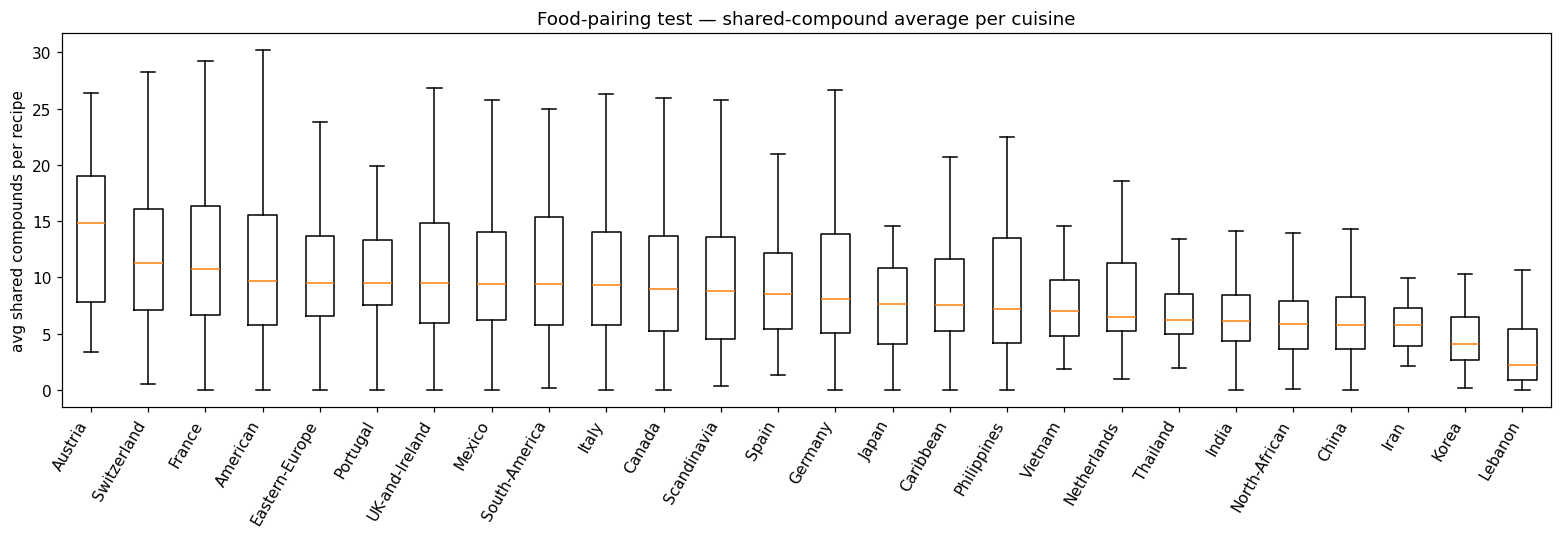

                count       mean
cuisine                         
Switzerland        20  14.410372
Austria            21  13.809785
France            266  12.541108
American        34943  12.017601
UK-and-Ireland    281  11.577823
South-America      99  11.376977
Eastern-Europe    235  11.020798
Portugal           49  11.013797
Canada            768  10.830911
Turkey             16  10.812324
Mexico           1752  10.809652
Italy            1457  10.775968


In [15]:
from itertools import combinations
import numpy as np

name_to_id  = dict(zip(ingr["ingredient name"], ingr["id"]))
id_to_comps = ic.groupby("ingredient_id")["compound_id"].apply(set).to_dict()

def avg_shared(ing_list):
    ids = [name_to_id[n] for n in ing_list if n in name_to_id]
    if len(ids) < 2:
        return np.nan
    vals = [len(id_to_comps.get(a, set()) & id_to_comps.get(b, set()))
            for a, b in combinations(ids, 2)]
    return float(np.mean(vals)) if vals else np.nan

rec_df = pd.DataFrame([{"cuisine": r[0], "ingredients": r[1:]} for r in recipes])
rec_df["avg_shared"] = rec_df["ingredients"].apply(avg_shared)
rec_df = rec_df.dropna(subset=["avg_shared"])

counts = rec_df["cuisine"].value_counts()
plot_df = rec_df[rec_df["cuisine"].isin(counts[counts >= 20].index)]
order = plot_df.groupby("cuisine")["avg_shared"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(max(9, len(order) * 0.55), 5), dpi=110)
ax.boxplot([plot_df.loc[plot_df.cuisine == c, "avg_shared"] for c in order],
           labels=order, showfliers=False)
ax.set_ylabel("avg shared compounds per recipe")
ax.set_title("Food-pairing test — shared-compound average per cuisine")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

print(rec_df.groupby("cuisine")["avg_shared"].agg(["count", "mean"])
        .sort_values("mean", ascending=False).head(12))

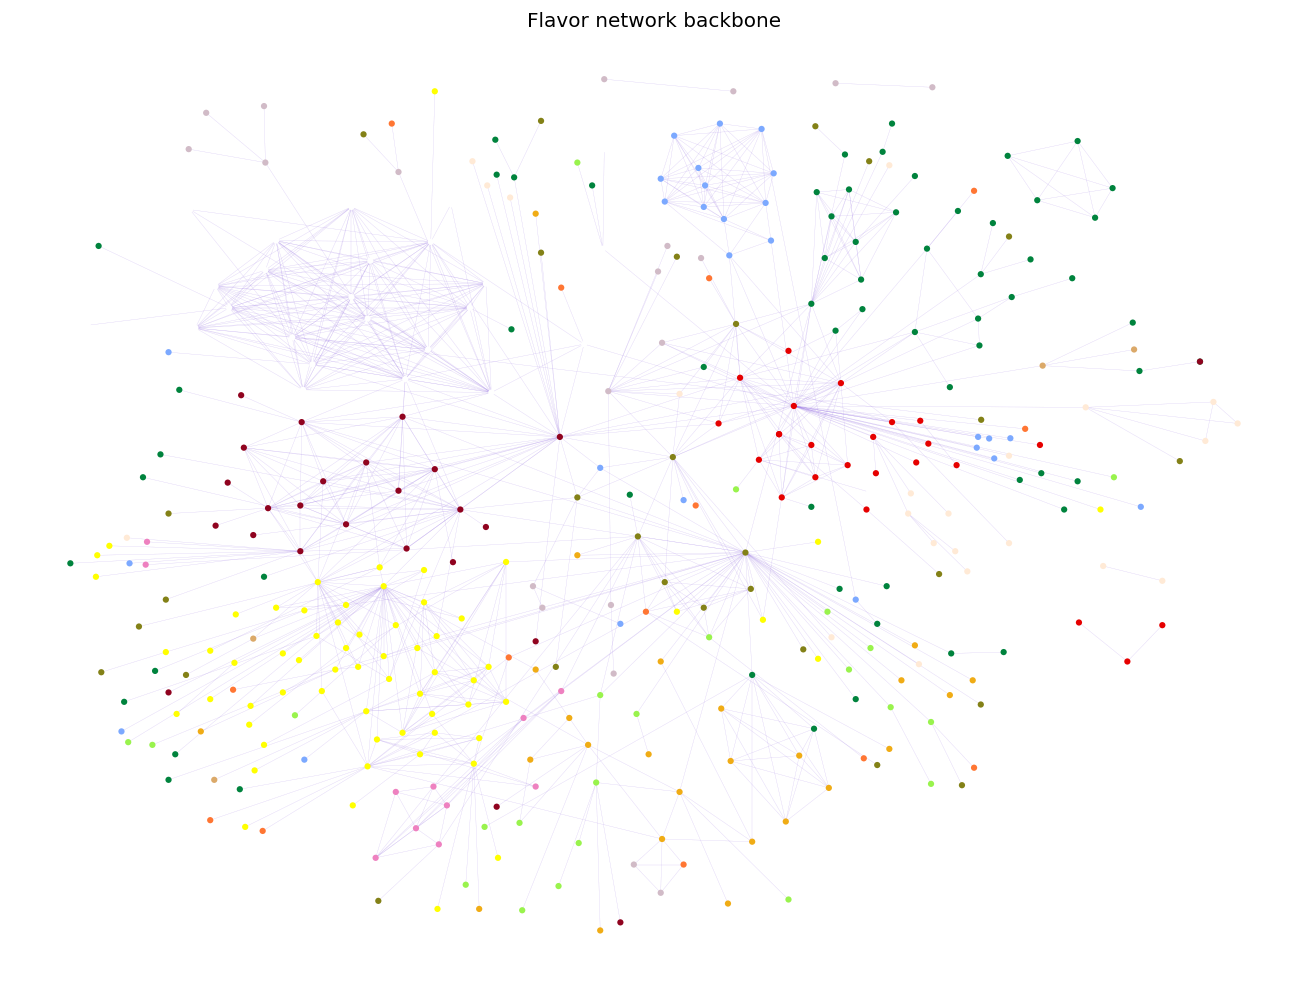

Plotted 376 nodes and 1834 edges


In [16]:
from matplotlib.collections import LineCollection

pos  = dict(zip(nodes["name"], zip(nodes["x"], nodes["y"])))
segs = [[pos[s], pos[d]] for s, d in zip(edges["src"], edges["dst"])
        if s in pos and d in pos]

rgb = nodes[["R", "G", "B"]].values.astype(float) / 255.0

fig, ax = plt.subplots(figsize=(11, 11), dpi=120)
ax.add_collection(LineCollection(segs, linewidths=0.15, alpha=0.25, colors="#9f7aea"))
ax.scatter(nodes["x"], nodes["y"], c=rgb, s=14, zorder=3, edgecolors="none")
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Flavor network backbone")
plt.tight_layout()
plt.show()

print(f"Plotted {len(nodes)} nodes and {len(segs)} edges")

15 communities found

Community 0 (size 83) — top categories:
?               28
vegetable       17
meat            11
fish/seafood     6
cereal/crop      4 

Community 1 (size 80) — top categories:
?            20
herb         15
spice        14
flower        8
vegetable     6 

Community 2 (size 55) — top categories:
fruit           31
?               12
vegetable        3
herb             2
fish/seafood     2 

Community 3 (size 46) — top categories:
?                     17
alcoholic beverage    10
vegetable              8
cereal/crop            4
fruit                  3 

Community 4 (size 35) — top categories:
?                   21
dairy                4
nut/seed/pulse       4
plant                2
plant derivative     1 

Community 5 (size 19) — top categories:
fruit        8
?            6
spice        1
vegetable    1
herb         1 

Community 6 (size 15) — top categories:
?              8
vegetable      6
cereal/crop    1 

Community 7 (size 15) — top categories:
fish/sea

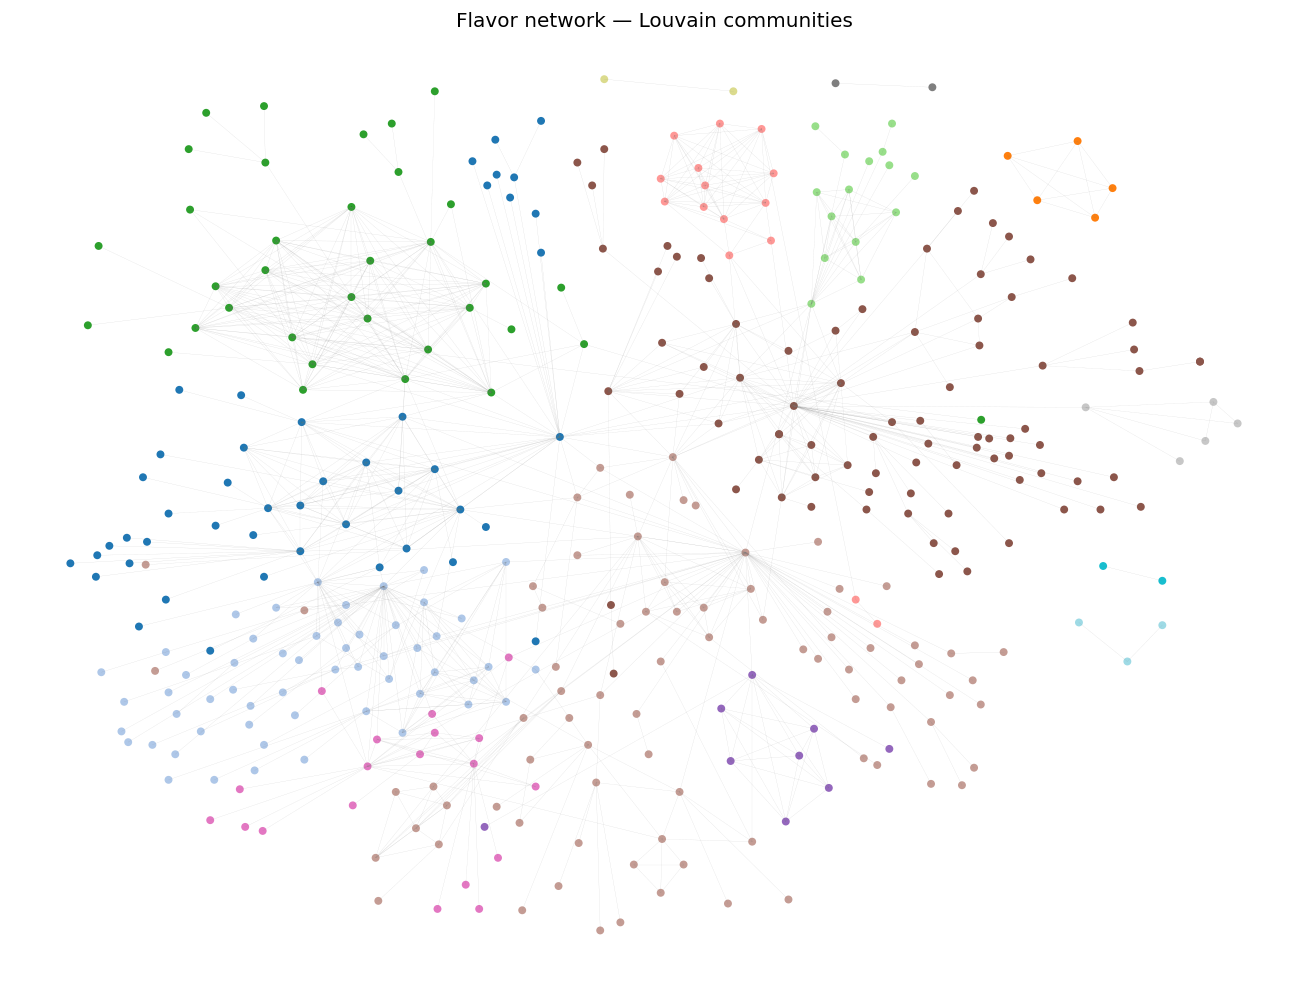

In [17]:
import networkx as nx
from networkx.algorithms.community import louvain_communities

G = nx.Graph()
for s, d, w in zip(edges["src"], edges["dst"], edges["weight"]):
    G.add_edge(s, d, weight=int(w))

comms = louvain_communities(G, weight="weight", seed=42)
print(f"{len(comms)} communities found\n")

name_to_cat = dict(zip(ingr["ingredient name"], ingr["category"]))
for i, c in enumerate(sorted(comms, key=len, reverse=True)[:8]):
    cats = pd.Series([name_to_cat.get(n, "?") for n in c]).value_counts().head(5)
    print(f"Community {i} (size {len(c)}) — top categories:")
    print(cats.to_string(), "\n")

# visualise communities
node_to_comm = {n: i for i, c in enumerate(comms) for n in c}
colors = [node_to_comm.get(n, -1) for n in nodes["name"]]

fig, ax = plt.subplots(figsize=(11, 11), dpi=120)
ax.add_collection(LineCollection(segs, linewidths=0.1, alpha=0.2, colors="gray"))
ax.scatter(nodes["x"], nodes["y"], c=colors, cmap="tab20", s=14)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Flavor network — Louvain communities")
plt.tight_layout()
plt.show()

In [18]:
deg = pd.Series(dict(G.degree(weight="weight"))).sort_values(ascending=False).head(15)
btw = (pd.Series(nx.betweenness_centrality(G, k=min(500, len(G)), seed=42))
         .sort_values(ascending=False).head(15))

print("Top weighted degree (most connected ingredients):")
print(deg.to_string())
print("\nTop betweenness (bridge ingredients):")
print(btw.to_string())

Top weighted degree (most connected ingredients):
roasted beef        2762
blue cheese         2653
parmesan cheese     2638
beer                2451
cheddar cheese      2424
strawberry          2331
swiss cheese        2312
gruyere cheese      2283
black tea           2275
camembert cheese    2193
romano cheese       2180
provolone cheese    2178
cottage cheese      2174
munster cheese      2173
cream cheese        2171

Top betweenness (bridge ingredients):
black tea          0.349444
roasted beef       0.323440
beer               0.268226
strawberry         0.143958
soybean            0.128124
white wine         0.121679
apple              0.121250
coffee             0.117033
orange             0.071847
parmesan cheese    0.054416
caviar             0.045173
beef               0.044792
raw beef           0.044792
blue cheese        0.042662
bell pepper        0.041745


mapped 578 of 1,834 edges (31.5%)


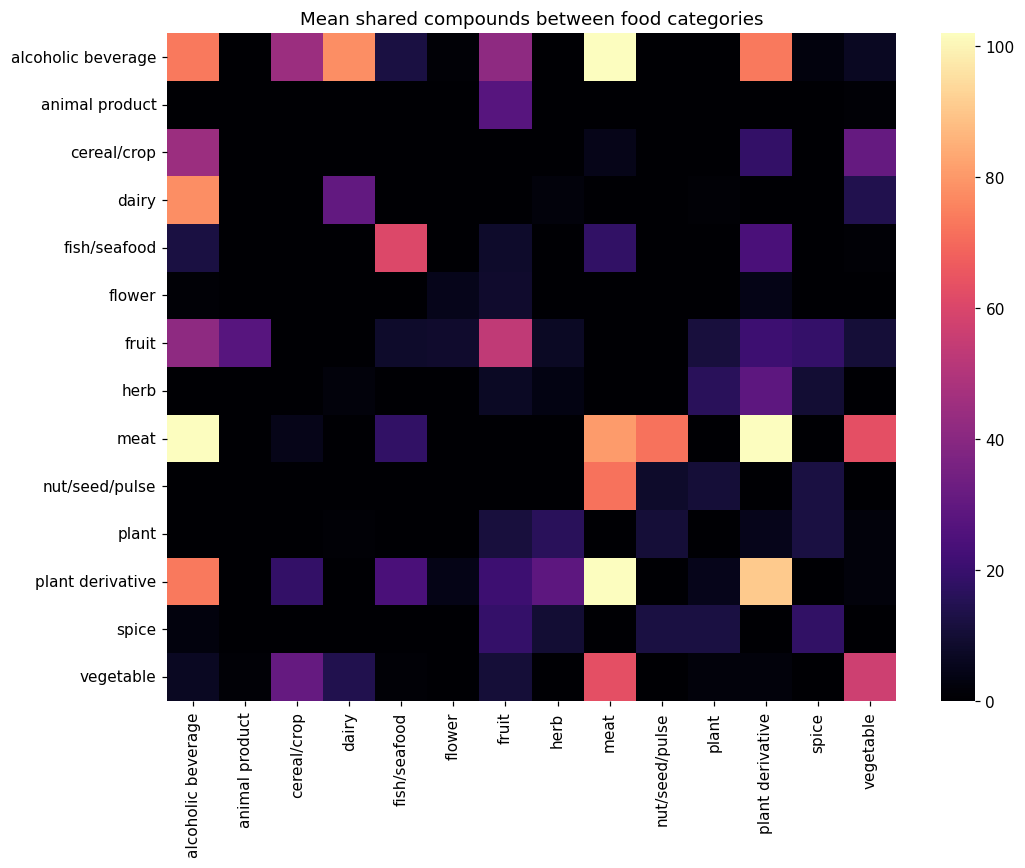

In [21]:
import seaborn as sns

# --- map ingredient NAME -> CATEGORY (not id -> category) ---
name_to_cat = dict(zip(ingr["ingredient name"], ingr["category"]))

cat_edges = edges.copy()
cat_edges["ca"] = cat_edges["src"].map(name_to_cat)
cat_edges["cb"] = cat_edges["dst"].map(name_to_cat)

mapped = cat_edges.dropna(subset=["ca", "cb"]).copy()
print(f"mapped {len(mapped):,} of {len(cat_edges):,} edges "
      f"({len(mapped)/len(cat_edges):.1%})")

if mapped.empty:
    raise RuntimeError(
        "No edges could be mapped to categories. "
        "Check that edges['src'] / edges['dst'] use the same ingredient names "
        "as ingr['ingredient name']."
    )

# --- symmetric category pair ---
mapped["A"] = mapped[["ca", "cb"]].min(axis=1)
mapped["B"] = mapped[["ca", "cb"]].max(axis=1)

pivot = mapped.groupby(["A", "B"])["weight"].mean().reset_index()
mat = pivot.pivot(index="A", columns="B", values="weight")
mat = mat.combine_first(mat.T).fillna(0)

# --- keep top 15 categories for readability ---
big = pd.concat([mapped["A"], mapped["B"]]).value_counts().head(15).index
mat = mat.loc[mat.index.isin(big), mat.columns.isin(big)]

# --- guard against an empty matrix ---
if mat.size == 0:
    raise RuntimeError("Heatmap matrix is empty after filtering.")

fig, ax = plt.subplots(figsize=(10, 8), dpi=110)
sns.heatmap(mat, cmap="magma", ax=ax)
ax.set_title("Mean shared compounds between food categories")
plt.tight_layout()
plt.show()

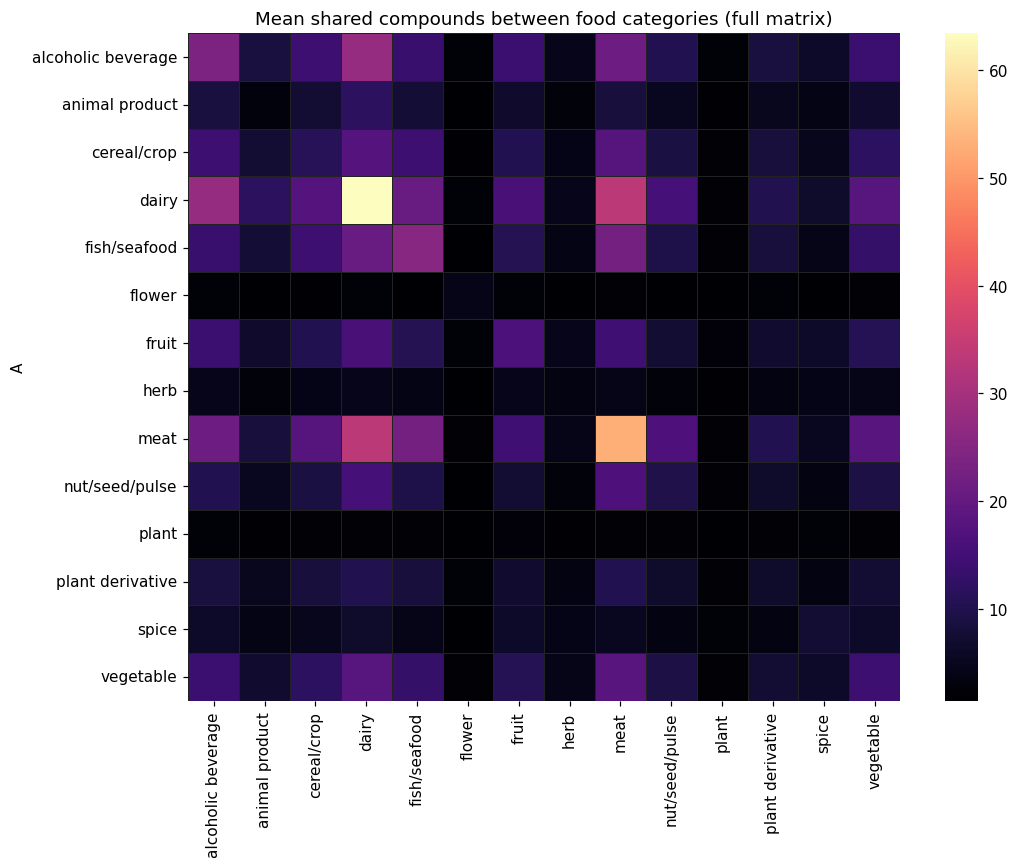

221,777 ingredient pairs contribute


In [22]:
import seaborn as sns
import numpy as np
from itertools import combinations

# --- 1. Lookup: ingredient id -> compound set, ingredient name -> id, id -> category ---
name_to_id  = dict(zip(ingr["ingredient name"], ingr["id"]))
id_to_cat   = dict(zip(ingr["id"], ingr["category"]))
id_to_comps = ic.groupby("ingredient_id")["compound_id"].apply(set).to_dict()

# --- 2. For every ingredient pair (not just the backbone), count shared compounds ---
rows = []
for a_id, b_id in combinations(id_to_comps.keys(), 2):
    n_shared = len(id_to_comps[a_id] & id_to_comps[b_id])
    if n_shared == 0:
        continue
    ca, cb = id_to_cat[a_id], id_to_cat[b_id]
    if ca is None or cb is None:
        continue
    A, B = sorted([ca, cb])
    rows.append((A, B, n_shared))

pair_df = pd.DataFrame(rows, columns=["A", "B", "shared"])

# --- 3. Mean shared compounds per category pair ---
pivot = pair_df.groupby(["A", "B"])["shared"].mean().reset_index()
mat = pivot.pivot(index="A", columns="B", values="shared")
mat = mat.combine_first(mat.T)

# --- 4. Restrict to top-15 categories, fill missing with NaN so seaborn shows them as blank ---
big = pd.concat([pair_df["A"], pair_df["B"]]).value_counts().head(15).index
mat = mat.loc[mat.index.isin(big), mat.columns.isin(big)]

fig, ax = plt.subplots(figsize=(10, 8), dpi=110)
sns.heatmap(mat, cmap="magma", ax=ax, mask=mat.isna(),
            linewidths=0.5, linecolor="#222")
ax.set_title("Mean shared compounds between food categories (full matrix)")
plt.tight_layout()
plt.show()

print(f"{len(pair_df):,} ingredient pairs contribute")